In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
data = np.load('cifar-10-python.npz')
x_train, x_test, y_train, y_test = data['x_train'], data['x_test'], data['y_train'], data['y_test']

In [3]:
m, n = np.max(x_train), np.min(x_train)
x_train, x_test = (x_train-n)/(m-n), (x_test-n)/(m-n)

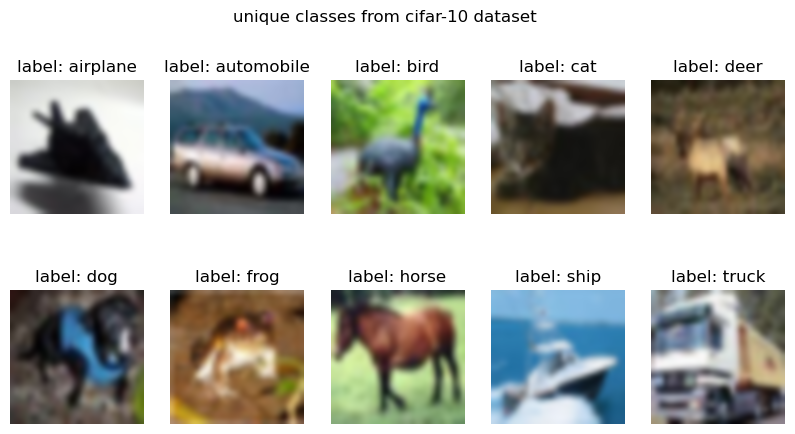

In [4]:
class_name = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
unique_labels, idx = np.unique(y_train, return_index = True)
fig, ax = plt.subplots(2,5, figsize=(10,5))
for i, label in enumerate(unique_labels):
    ax.flat[i].imshow(x_train[idx[i]], interpolation = 'bicubic')
    ax.flat[i].set_title(f"label: {class_name[label]}")
    ax.flat[i].axis("off")
plt.suptitle("unique classes from cifar-10 dataset")
plt.show()

In [6]:
learning_rates = [0.001, 0.005, 0.01, 0.05, 0.1]
histories=[]
accuracies = []
for lr in learning_rates:
    print(f"\n--- Traininig Model with Learning rate: {lr} ---")
    model = keras.Sequential([
        layers.Flatten(input_shape=(32,32,3)),
        layers.Dense(256, activation = 'relu'),
        layers.Dropout(0.2),
        layers.Dense(128, activation = 'relu'),
        layers.Dropout(0.2),
        layers.Dense(64, activation = 'relu'),
        layers.Dense(10, activation ='softmax')
    ])
    model.compile(optimizer= keras.optimizers.SGD(learning_rate=lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    early_stop = keras.callbacks.EarlyStopping(monitor= 'val_loss', patience=3, restore_best_weights=True)

    history = model.fit(x_train, y_train, epochs= 10, validation_split=0.2, callbacks=[early_stop], verbose =1)
    histories.append(history)

    loss, acc = model.evaluate(x_test, y_test, verbose=1)
    accuracies.append(acc)
        


--- Traininig Model with Learning rate: 0.001 ---
Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.1520 - loss: 2.2508 - val_accuracy: 0.2318 - val_loss: 2.1509
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.2134 - loss: 2.1344 - val_accuracy: 0.2673 - val_loss: 2.0467
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2482 - loss: 2.0567 - val_accuracy: 0.2978 - val_loss: 1.9802
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.2781 - loss: 1.9991 - val_accuracy: 0.3076 - val_loss: 1.9385
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2859 - loss: 1.9635 - val_accuracy: 0.3151 - val_loss: 1.9069
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.3005 - loss: 1.9324 - val_accuracy: 0.3261 - val_loss: 1.8822
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.3133 - loss: 1.9088 - val_accuracy: 0.3371 - val_loss: 1.8650
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━

In [7]:
print("\n Final Test Accuracy Comparision: ")
for lr, acc in zip(learning_rates, accuracies):
    print(f"Learning Rate {lr} : {acc*100:.2f}%")


 Final Test Accuracy Comparision: 
Learning Rate 0.001 : 36.76%
Learning Rate 0.005 : 45.54%
Learning Rate 0.01 : 47.07%
Learning Rate 0.05 : 45.87%
Learning Rate 0.1 : 42.44%


enter image index (0-9999):  0


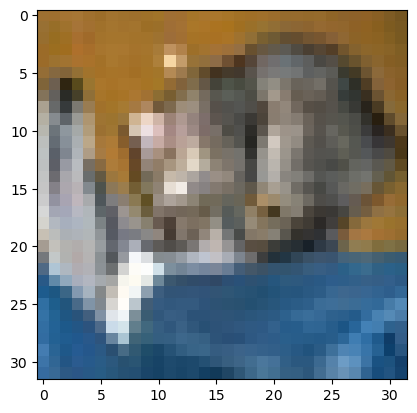

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Predicted Class:  cat
Actual Class:  cat


In [21]:
#Prediction
image_idx = int(input("enter image index (0-9999): "))
plt.imshow(x_test[image_idx])
plt.show()
prediction = histories[2].model.predict(x_test[image_idx].reshape(1,32,32,3))
print("Predicted Class: ", class_name[np.argmax(prediction[0])])
print("Actual Class: ", class_name[y_test[image_idx]])

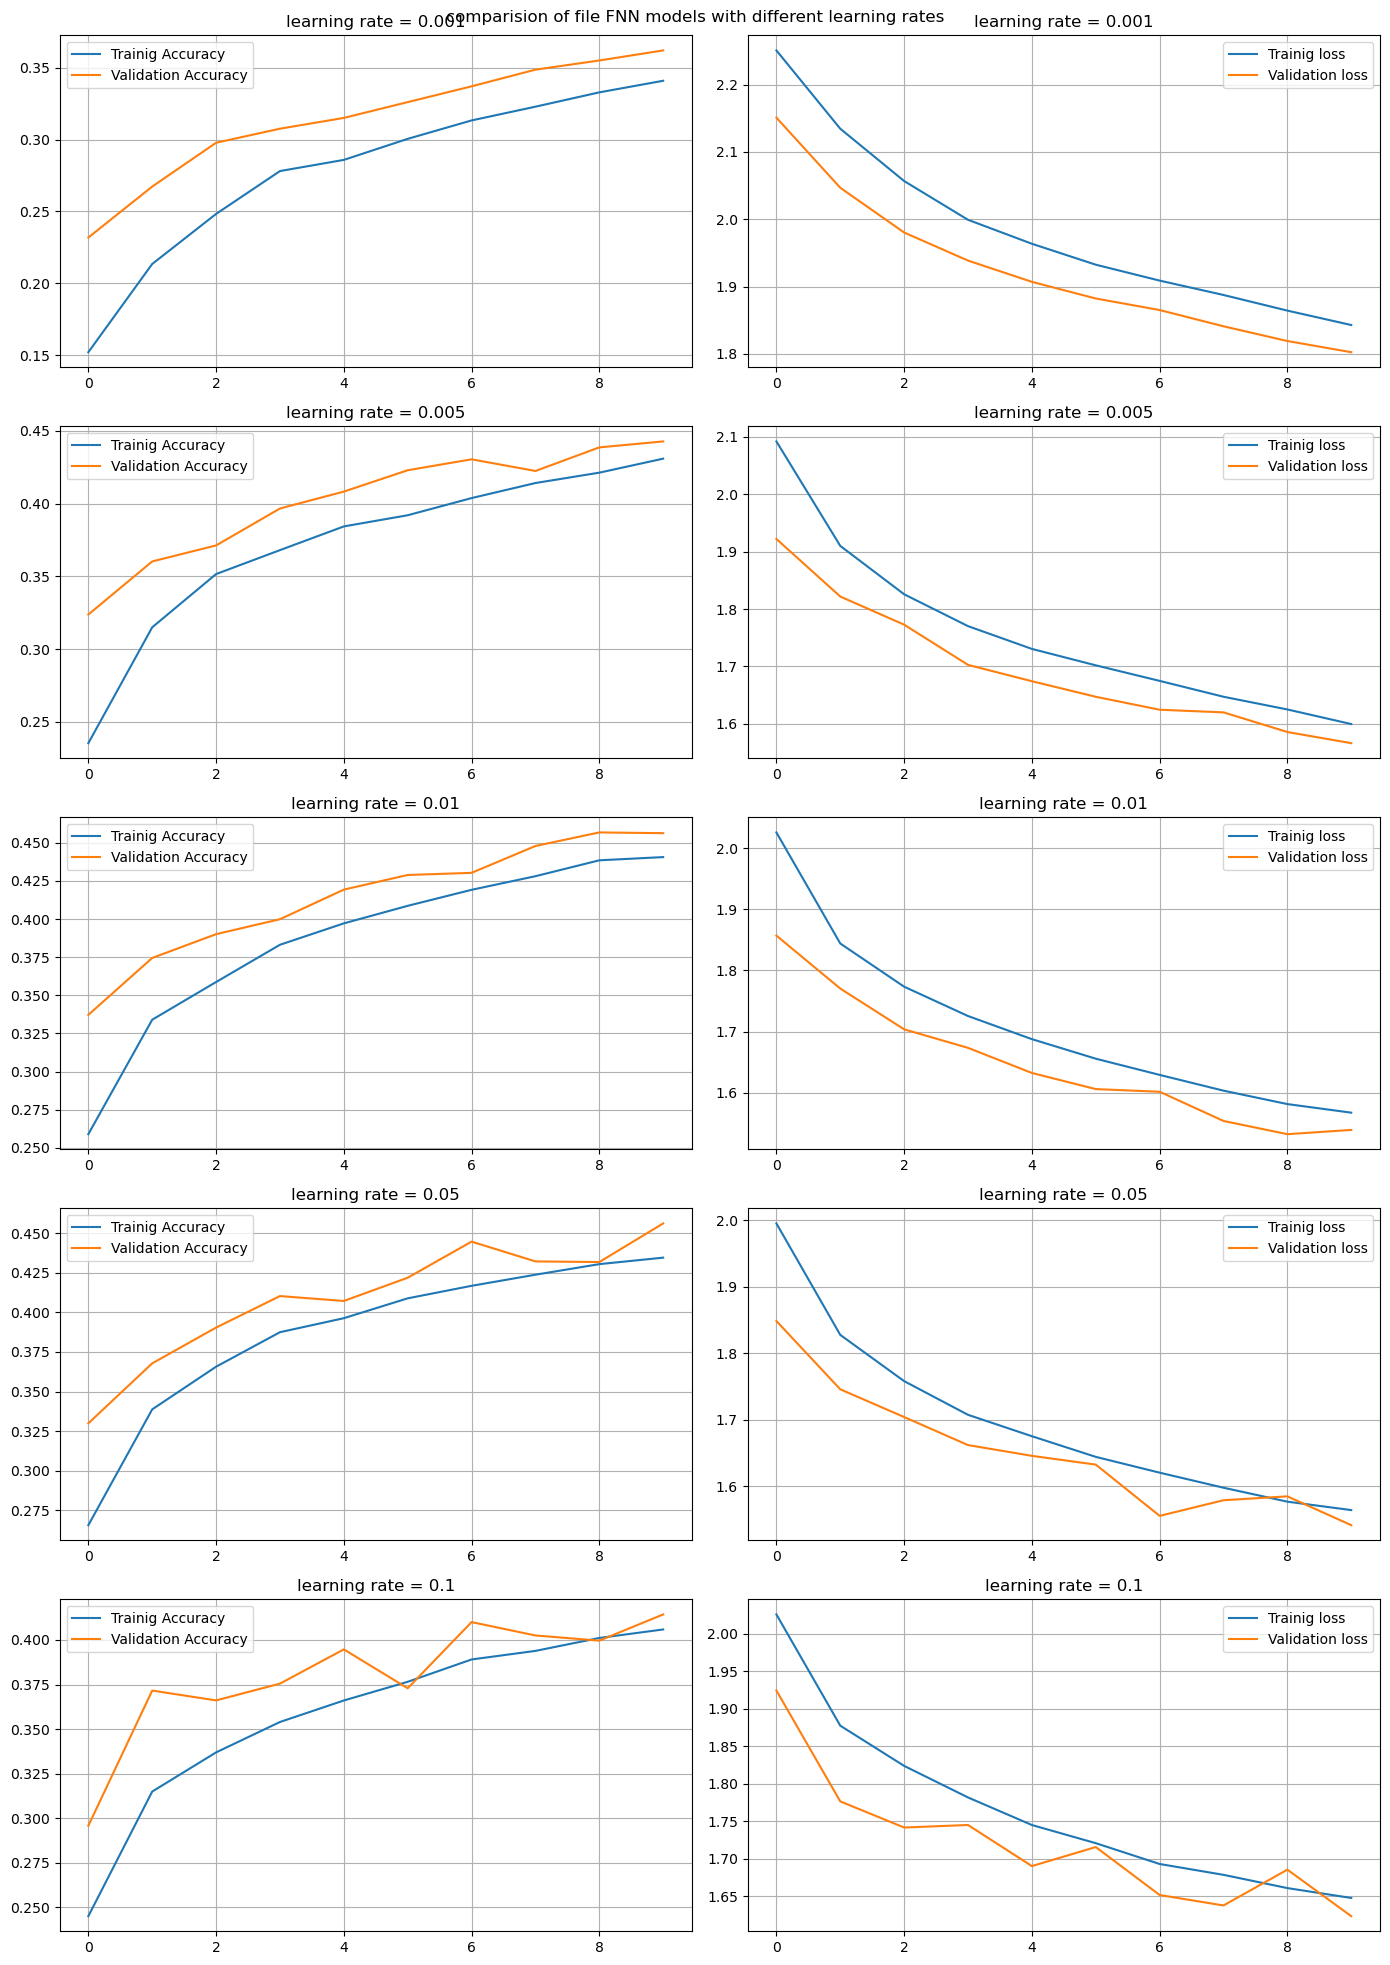

In [23]:
fig, ax = plt.subplots(5,2, figsize=(14,20))
for i , history in enumerate(histories):
    #Accuracy plot
    ax[i,0].plot(history.history['accuracy'], label="Trainig Accuracy")
    ax[i,0].plot(history.history['val_accuracy'], label="Validation Accuracy")
    ax[i,0].set_title(f"learning rate = {learning_rates[i]}")
    ax[i,0].legend()
    ax[i,0].grid(True)

    #loss plot
    ax[i,1].plot(history.history['loss'], label="Trainig loss")
    ax[i,1].plot(history.history['val_loss'], label="Validation loss")
    ax[i,1].set_title(f"learning rate = {learning_rates[i]}")
    ax[i,1].legend()
    ax[i,1].grid(True)
plt.suptitle("comparision of file FNN models with different learning rates")
plt.tight_layout()
plt.show()
    